 Task 2

Take a small dataset

Perform:

Step 1: Behavioral Features

Extract: word count, average word length, exclamation marks, uppercase ratio.

Step 2: Linguistic Features

Build a Bag-of-Words table.

Compute Term Frequency (TF).

Step 3: Visualizations

Plot distribution of word counts by class.

Compare average TF of at least 4 selected words across suicidal vs non-suicidal.

Step 4: Reflection
Write 3–5 sentences:

Which behavioral feature shows biggest difference?

Which words (from TF) are stronger signals for suicidal vs non-suicidal?

If you had to design a model today, which 3 features would you pick first and why?

#STEP 0: IMPORT THE LIBRARIES AND BUILD THE DATASET:

In [2]:
# 1. Import libraries
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# 2. Create a small dataset
data = {
    "text": [
        "I feel hopeless and want to give up",
        "Sometimes I think about not being here anymore",
        "I don't see the point of anything anymore",
        "I wish I could just disappear forever",
        "Everyone would be better off without me",
        "I'm tired of living like this",
        "I can't do this anymore, I want it all to end",
        "Nothing will ever get better for me",
        "I feel like a burden to everyone around me",
        "I've been thinking that life isn't worth living",
        "I don't want to wake up tomorrow",
        "There is no reason for me to keep going",
        "I feel completely trapped and see no way out",
        "I keep thinking the world would be fine without me",
        "I am so exhausted with being alive",
        "I just want the pain to stop permanently",
        "No one would even notice if I was gone",
        "I've lost all hope for my future",
        "I think about ending my life more and more",
        "I feel empty and I don't want to exist anymore",
        "Nobody cares whether I live or die",
        "I can't see myself being alive next year",
        "I wish I had never been born",
        "Every day I wonder why I am still here",
        "I'm done with everything, I'm done with life",
        "I feel like giving up on life entirely",
        "The thought of not existing feels like relief",
        "I have nothing left to live for",
        "I don't think I can survive this pain, and part of me doesn't want to",
        "I keep imagining a world where I'm not around",
        "Life has become unbearable and I want out",
        "I've been having thoughts of ending it all",
        "I feel like the only way out is to not be alive",
        "I am worthless and the world doesn't need me",
        "I'm so tired of fighting to stay alive",
        "I don't have the will to keep living",
        "I told my friends goodbye because I don't plan to be around",
        "I can't go on like this, it's too much",
        "Sometimes I wish I would just not wake up",
        "I feel like my life has no purpose and never will",
        "I am scared because I want to die",
        "I have been thinking that death would be easier than this",
        "I can't stop thinking about dying",
        "There's just no future for me anymore",
        "I feel so alone that I want to stop existing",
        "It hurts too much to keep living",
        "I don't want to be alive anymore",
        "I have given up and I don't care what happens to me",
        "My family would be happier if I were gone",
        "I feel like ending my life is the only solution left",
        "Life is beautiful, I love spending time with friends",
        "Today is a great day, full of energy!",
        "I'm so excited for my trip next week",
        "Just finished a great workout, feeling strong",
        "I love cooking dinner for my family on Sundays",
        "This exam is killing me, I need a coffee break",
        "I'm feeling a bit sad today, but talking to a friend helped",
        "Work has been stressful, but I'm managing okay",
        "Can't wait for the weekend to go hiking",
        "I just adopted a puppy and he's adorable",
        "I'm really proud of my progress in learning guitar",
        "The sunset tonight was absolutely gorgeous",
        "I had a rough day, but tomorrow is a fresh start",
        "Looking forward to seeing my parents this holiday",
        "I got the job offer! I'm thrilled",
        "I'm tired after a long day, going to bed early",
        "My favorite band is coming to town next month",
        "I'm frustrated with traffic, but the podcast is good",
        "We celebrated my sister's birthday with a big cake",
        "I need to finish this project by Friday",
        "Reading a fantastic novel right now, can't put it down",
        "I feel nervous about my presentation, but I'm prepared",
        "The weather is lovely, let's have a picnic",
        "I'm learning to bake sourdough bread and it's fun",
        "Going through a breakup hurts, but I know I'll heal",
        "I laughed so hard at that movie last night",
        "I'm grateful for my friends and their support",
        "Started a new hobby: painting landscapes",
        "My team won the match, what a game!",
        "I'm stressed about deadlines, time to make a plan",
        "Had a lovely walk in the park this morning",
        "I feel much better after a good night's sleep",
        "Can anyone recommend a good pizza place nearby?",
        "I am so bored today, nothing to do",
        "I miss my old friends, I should call them",
        "Just booked tickets to see my favorite museum",
        "I'm overwhelmed with chores, but I'll get through them",
        "I feel motivated to start my day with some yoga",
        "The new coffee shop downtown is amazing",
        "My kids made me a card, it made my whole day",
        "I'm disappointed I lost, but I'll try again next season",
        "Studying late tonight for my chemistry test",
        "I'm so happy that spring has finally arrived",
        "Feeling anxious about moving, but also excited",
        "We are planning a surprise party for my best friend",
        "I finished my first 10k run today!",
        "Grief is hard, but I'm leaning on my family for support",
        "My phone battery is dying, I need to find a charger",
        "I love listening to music while I code",
        "Today I felt lonely, so I joined a local book club",
    ],
    "label": [
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    ]
}

df = pd.DataFrame(data)
print("Original Dataset:\n")
print(df)

Original Dataset:

                                                 text  label
0                 I feel hopeless and want to give up      1
1      Sometimes I think about not being here anymore      1
2           I don't see the point of anything anymore      1
3               I wish I could just disappear forever      1
4             Everyone would be better off without me      1
..                                                ...    ...
95                 I finished my first 10k run today!      0
96  Grief is hard, but I'm leaning on my family fo...      0
97  My phone battery is dying, I need to find a ch...      0
98             I love listening to music while I code      0
99  Today I felt lonely, so I joined a local book ...      0

[100 rows x 2 columns]


#Step 1: Behavioral Features

In [5]:
# Step 1: Behavioral features
df['word_count'] = df['text'].apply(lambda x: len(x.split()))
df['avg_word_len'] = df['text'].apply(lambda x: sum(len(w) for w in x.split()) / len(x.split()))
df['exclamations'] = df['text'].str.count('!')
df['upper_ratio'] = df['text'].apply(lambda x: sum(c.isupper() for c in x) / len(x))
print(df.groupby('label')[['word_count','avg_word_len','exclamations','upper_ratio']].mean())

       word_count  avg_word_len  exclamations  upper_ratio
label                                                     
0            8.74      4.356579          0.08     0.030123
1            8.64      3.900300          0.00     0.034859


#Step 2: Linguistic Features

 PART A: Word Frequency with CountVectorizer (Bag-of-Words)

Prepares a Bag-of-Words transformer.

No output yet.

In [ ]:
# 3. Initialize CountVectorizer
vectorizer = CountVectorizer()
print(vectorizer)

CountVectorizer()


Learns the vocabulary (all unique words).

Transforms each text into a sparse matrix of word counts.

No visible output here.

In [ ]:
# 4. Fit and transform the text column
X = vectorizer.fit_transform(df['text'])
print(X)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 748 stored elements and shape (100, 355)>
  Coords	Values
  (0, 98)	1
  (0, 152)	1
  (0, 13)	1
  (0, 327)	1
  (0, 310)	1
  (0, 122)	1
  (0, 322)	1
  (1, 273)	1
  (1, 300)	1
  (1, 1)	1
  (1, 214)	1
  (1, 31)	1
  (1, 147)	1
  (1, 15)	1
  (2, 15)	1
  (2, 73)	1
  (2, 264)	1
  (2, 296)	1
  (2, 244)	1
  (2, 219)	1
  (2, 17)	1
  (3, 342)	1
  (3, 63)	1
  (3, 162)	1
  (3, 69)	1
  :	:
  (96, 134)	1
  (96, 171)	1
  (97, 310)	1
  (97, 157)	1
  (97, 203)	1
  (97, 206)	1
  (97, 77)	1
  (97, 237)	1
  (97, 24)	1
  (97, 104)	1
  (97, 54)	1
  (98, 310)	1
  (98, 186)	1
  (98, 177)	1
  (98, 202)	1
  (98, 338)	1
  (98, 58)	1
  (99, 270)	1
  (99, 311)	1
  (99, 101)	1
  (99, 182)	1
  (99, 161)	1
  (99, 181)	1
  (99, 37)	1
  (99, 57)	1


Converts the Bag-of-Words matrix into a readable table.

Columns = words, Rows = posts.

Values = how many times each word appears.

In [ ]:
# 5. Convert result to DataFrame
bow_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
print("\nBag-of-Words Representation:\n")
print(bow_df)


Bag-of-Words Representation:

    10k  about  absolutely  adopted  adorable  after  again  alive  all  \
0     0      0           0        0         0      0      0      0    0   
1     0      1           0        0         0      0      0      0    0   
2     0      0           0        0         0      0      0      0    0   
3     0      0           0        0         0      0      0      0    0   
4     0      0           0        0         0      0      0      0    0   
..  ...    ...         ...      ...       ...    ...    ...    ...  ...   
95    1      0           0        0         0      0      0      0    0   
96    0      0           0        0         0      0      0      0    0   
97    0      0           0        0         0      0      0      0    0   
98    0      0           0        0         0      0      0      0    0   
99    0      0           0        0         0      0      0      0    0   

    alone  ...  won  wonder  work  workout  world  worth  worthless 

Adds the label column back to the Bag-of-Words table.

Useful for comparing suicidal vs non-suicidal texts.

👉 Output: Same as above, but with a label column.

In [ ]:
# Combine with labels
bow_with_labels = pd.concat([df[['label']], bow_df], axis=1)
print("\nBag-of-Words with Labels:\n")
print(bow_with_labels)


Bag-of-Words with Labels:

    label  10k  about  absolutely  adopted  adorable  after  again  alive  \
0       1    0      0           0        0         0      0      0      0   
1       1    0      1           0        0         0      0      0      0   
2       1    0      0           0        0         0      0      0      0   
3       1    0      0           0        0         0      0      0      0   
4       1    0      0           0        0         0      0      0      0   
..    ...  ...    ...         ...      ...       ...    ...    ...    ...   
95      0    1      0           0        0         0      0      0      0   
96      0    0      0           0        0         0      0      0      0   
97      0    0      0           0        0         0      0      0      0   
98      0    0      0           0        0         0      0      0      0   
99      0    0      0           0        0         0      0      0      0   

    all  ...  won  wonder  work  workout  world

PART B: Inspect Vocabulary

Prints all unique words in dataset.

Prints total frequency of each word across all posts.

👉 Output: A list of words and how often they appear (e.g., “I” = 5, “sad” = 1).

In [ ]:
print("\nVocabulary (all unique words):")
print(vectorizer.get_feature_names_out())

print("\nWord counts across all posts:")
print(bow_df.sum(axis=0).sort_values(ascending=False))


Vocabulary (all unique words):
['10k' 'about' 'absolutely' 'adopted' 'adorable' 'after' 'again' 'alive'
 'all' 'alone' 'also' 'am' 'amazing' 'and' 'anxious' 'anymore' 'anyone'
 'anything' 'are' 'around' 'arrived' 'at' 'bake' 'band' 'battery' 'be'
 'beautiful' 'because' 'become' 'bed' 'been' 'being' 'best' 'better' 'big'
 'birthday' 'bit' 'book' 'booked' 'bored' 'born' 'bread' 'break' 'breakup'
 'burden' 'but' 'by' 'cake' 'call' 'can' 'card' 'care' 'cares'
 'celebrated' 'charger' 'chemistry' 'chores' 'club' 'code' 'coffee'
 'coming' 'completely' 'cooking' 'could' 'day' 'deadlines' 'death' 'die'
 'dinner' 'disappear' 'disappointed' 'do' 'doesn' 'don' 'done' 'down'
 'downtown' 'dying' 'early' 'easier' 'empty' 'end' 'ending' 'energy'
 'entirely' 'even' 'ever' 'every' 'everyone' 'everything' 'exam' 'excited'
 'exhausted' 'exist' 'existing' 'family' 'fantastic' 'favorite' 'feel'
 'feeling' 'feels' 'felt' 'fighting' 'finally' 'find' 'fine' 'finish'
 'finished' 'first' 'for' 'forever' 'forwar

#Step 3: Visualizations:

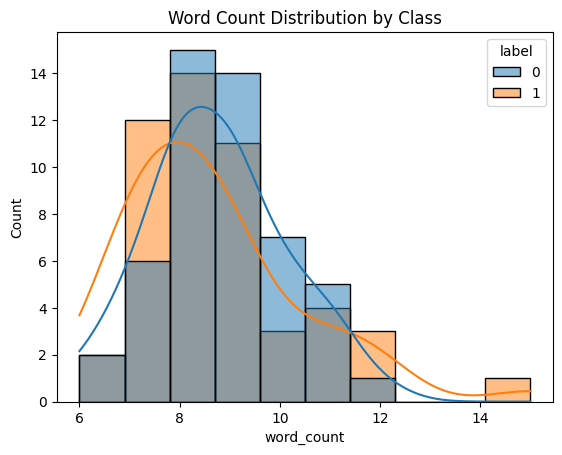

In [11]:
# Step 3: Word count distribution by class
sns.histplot(data=df, x='word_count', hue='label', kde=True, bins=10)
plt.title("Word Count Distribution by Class")
plt.show()

PART C: Term Frequency (TF)

Normalizes word counts by total words per post.

Ensures short vs long posts are comparable.

👉 Output: Table where values are fractions (e.g., “sad” = 0.25).

In [ ]:
# 6. Compute Term Frequency manually
tf_df = bow_df.div(bow_df.sum(axis=1), axis=0)
print("\nTerm Frequency (normalized word counts):\n")
print(tf_df)


Term Frequency (normalized word counts):

         10k     about  absolutely  adopted  adorable  after  again  alive  \
0   0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
1   0.000000  0.142857         0.0      0.0       0.0    0.0    0.0    0.0   
2   0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
3   0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
4   0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
..       ...       ...         ...      ...       ...    ...    ...    ...   
95  0.166667  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
96  0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
97  0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
98  0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   
99  0.000000  0.000000         0.0      0.0       0.0    0.0    0.0    0.0   

    all  alone  ... 

PART D: Visualization

Plots a bar chart of word frequencies.

👉 Output: Bars showing most common words in dataset.

Interpretation: Common words like I, am, and appear more often; suicidal cues like sad, die are rarer but important.

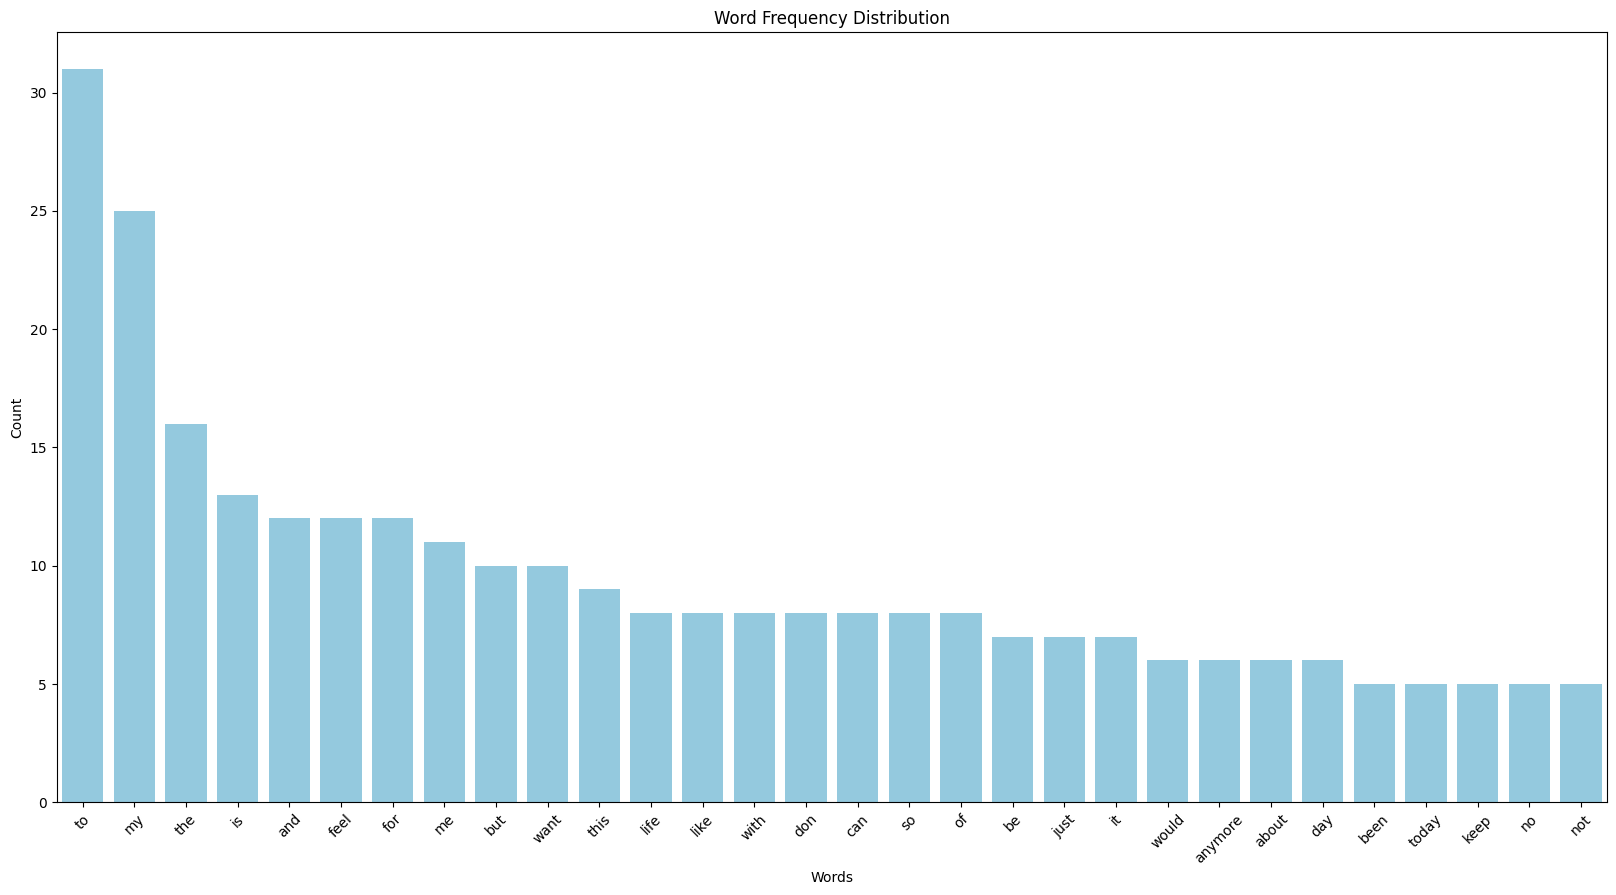

In [ ]:
# Word frequency distribution
n_words = 30

word_counts = bow_df.sum(axis=0).sort_values(ascending=False)
top = word_counts.head(n_words)

plt.figure(figsize=(20,10))
sns.barplot(x=top.index, y=top.values, color="skyblue")
plt.title("Word Frequency Distribution")
plt.xlabel("Words")
plt.ylabel("Count")
plt.xticks(rotation=45, fontsize=10)
plt.show()

#Step 4: Reflection:


Groups posts by label.

Computes average TF for suicidal vs non-suicidal.

👉 Output: Table showing how often each word appears on average in suicidal vs non-suicidal posts.

In [ ]:
# Compare suicidal vs non-suicidal average TF
tf_with_labels = pd.concat([df[['label']], tf_df], axis=1)
avg_tf = tf_with_labels.groupby('label').mean().T

print("\nAverage Term Frequency by Class:\n")
print(avg_tf)


Average Term Frequency by Class:

label              0         1
10k         0.003333  0.000000
about       0.008571  0.009357
absolutely  0.003333  0.000000
adopted     0.003333  0.000000
adorable    0.003333  0.000000
...              ...       ...
worth       0.000000  0.002500
worthless   0.000000  0.002500
would       0.000000  0.014937
year        0.000000  0.002857
yoga        0.002222  0.000000

[355 rows x 2 columns]


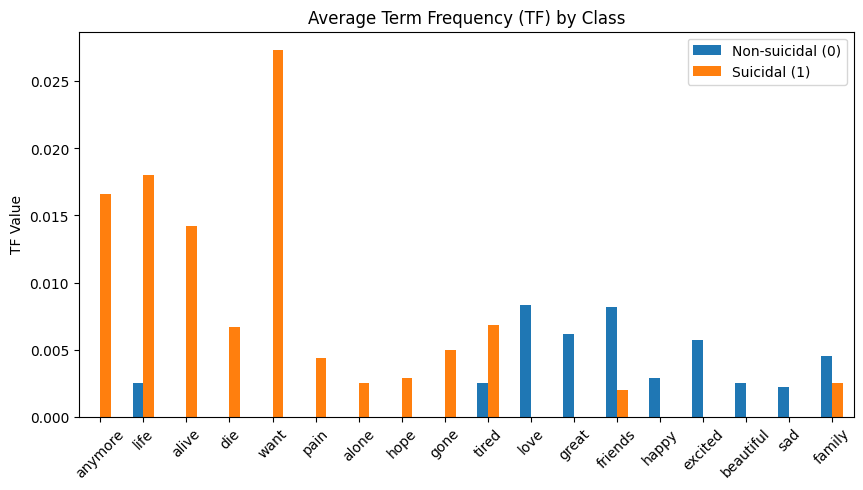

In [ ]:
# Plot comparison for a few selected words
selected_words = [
    'anymore', 'life', 'alive', 'die', 'want', 'pain', 'alone', 'hope', 'gone', 'tired',
    'love', 'great', 'friends', 'happy', 'excited', 'beautiful', 'sad', 'family'
]
avg_tf.loc[selected_words].plot(kind='bar', figsize=(10,5))
plt.title("Average Term Frequency (TF) by Class")
plt.ylabel("TF Value")
plt.xticks(rotation=45)
plt.legend(['Non-suicidal (0)', 'Suicidal (1)'])
plt.show()

Exclamation marks show the biggest difference. Only non-suicidal posts use them, like “I got the job offer!” Word count and word length differ a little, and uppercase ratio is almost the same.

Words like anymore, life, alive, die, want, and pain are stronger signals for suicidal posts, while love, great, friends, and happy point to non-suicidal ones.

I’d start with three features: TF of key words like anymore and want, exclamation count, and word count. They’re simple and show clear differences. With only 100 posts, these results are just a hint, not proof.